In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import ast

# 1. Analisis Inicial
### Abrimos los Dataframes

In [2]:
df_customers = pd.read_csv(r"C:\Users\Adrian\Desktop\CODE_SPACE\Ejercicios\Python_Basics_for_DS\data\cafe_rewards_offers\customers.csv")
df_offers = pd.read_csv(r"C:\Users\Adrian\Desktop\CODE_SPACE\Ejercicios\Python_Basics_for_DS\data\cafe_rewards_offers\offers.csv")
df_events = pd.read_csv(r"C:\Users\Adrian\Desktop\CODE_SPACE\Ejercicios\Python_Basics_for_DS\data\cafe_rewards_offers\events.csv")


In [3]:
# Forma de cada Dataframe

print('customers: ', df_customers.shape)
print('offers: ', df_offers.shape)
print('events: ', df_events.shape)

customers:  (17000, 5)
offers:  (10, 6)
events:  (306534, 4)


### Tabla Customers


In [4]:
display(df_customers.head())
display(df_customers.info())

,customer_id,became_member_on,gender,age,income
0,68be06ca386d4c31939f3a4f0e3dd783,20170212,NaN,118,NaN
1,0610b486422d4921ae7d2bf64640c50b,20170715,F,55,112000.0
2,38fe809add3b4fcf9315a9694bb96ff5,20180712,NaN,118,NaN
3,78afa995795e4d85b5d9ceeca43f5fef,20170509,F,75,100000.0
4,a03223e636434f42ac4c3df47e8bac43,20170804,NaN,118,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       17000 non-null  object 
 1   became_member_on  17000 non-null  int64  
 2   gender            14825 non-null  object 
 3   age               17000 non-null  int64  
 4   income            14825 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 664.2+ KB


None

### Tabla Events

In [5]:
display(df_events.head())
display(df_events.info())

,customer_id,event,value,time
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0
1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0
2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0
3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},0
4,68617ca6246f4fbc85e91a2a49552598,offer received,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306534 entries, 0 to 306533
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   customer_id  306534 non-null  object
 1   event        306534 non-null  object
 2   value        306534 non-null  object
 3   time         306534 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 9.4+ MB


None

### Tabla Offers

In [6]:
display(df_offers.head())
display(df_offers.info())

,offer_id,offer_type,difficulty,reward,duration,channels
0,ae264e3637204a6fb9bb56bc8210ddfd,bogo,10,10,7,"['email', 'mobile', 'social']"
1,4d5c57ea9a6940dd891ad53e9dbe8da0,bogo,10,10,5,"['web', 'email', 'mobile', 'social']"
2,3f207df678b143eea3cee63160fa8bed,informational,0,0,4,"['web', 'email', 'mobile']"
3,9b98b8c7a33c4b65b9aebfe6a799e6d9,bogo,5,5,7,"['web', 'email', 'mobile']"
4,0b1e1539f2cc45b7b9fa7c272da2e1d7,discount,20,5,10,"['web', 'email']"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   offer_id    10 non-null     object
 1   offer_type  10 non-null     object
 2   difficulty  10 non-null     int64 
 3   reward      10 non-null     int64 
 4   duration    10 non-null     int64 
 5   channels    10 non-null     object
dtypes: int64(3), object(3)
memory usage: 612.0+ bytes


None

## Nulls


In [7]:
display((df_customers.isnull().sum() / len(df_customers))*100)
display((df_events.isnull().sum() / len(df_events))*100)
display((df_offers.isnull().sum() / len(df_offers))*100)

customer_id          0.000000
became_member_on     0.000000
gender              12.794118
age                  0.000000
income              12.794118
dtype: float64

customer_id    0.0
event          0.0
value          0.0
time           0.0
dtype: float64

offer_id      0.0
offer_type    0.0
difficulty    0.0
reward        0.0
duration      0.0
channels      0.0
dtype: float64

## Outliers

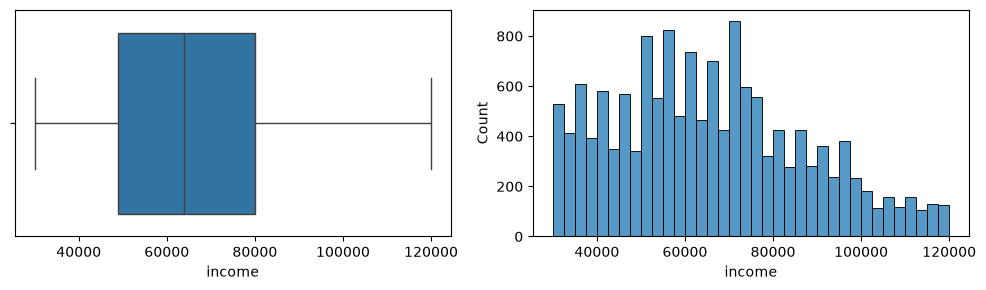

In [8]:
fig, axes = plt.subplots(1,2,figsize=(10,3))
sns.boxplot(data=df_customers, x='income', ax=axes[0])
sns.histplot(data=df_customers, x='income', ax=axes[1])

plt.tight_layout() #Ajusta los espacios para evitar solapamientos

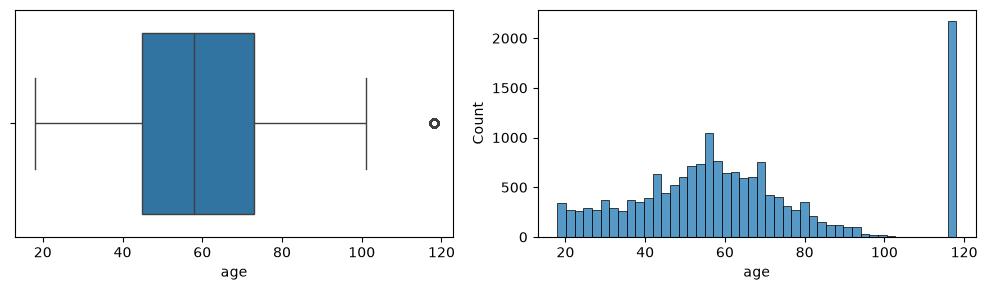

In [9]:
fig, axes = plt.subplots(1,2,figsize=(10,3))
sns.boxplot(data=df_customers, x='age', ax=axes[0])
sns.histplot(data=df_customers, x='age', ax=axes[1])

plt.tight_layout() #Ajusta los espacios para evitar solapamientos

In [10]:
df_customers['gender'].unique()

array([nan, 'F', 'M', 'O'], dtype=object)

CONCLUSIONES:
- Gestionar Nans de gender e income
- became_member_on -> Fecha
- Gestionar outliers en age

In [11]:
customers_clean = df_customers.copy()

In [12]:
#became member on a Fecha

customers_clean['became_member_on'] = pd.to_datetime(customers_clean['became_member_on'], format='%Y%m%d' , errors='coerce')

In [13]:
display(df_customers.head())
display(customers_clean.head())

,customer_id,became_member_on,gender,age,income
0,68be06ca386d4c31939f3a4f0e3dd783,20170212,NaN,118,NaN
1,0610b486422d4921ae7d2bf64640c50b,20170715,F,55,112000.0
2,38fe809add3b4fcf9315a9694bb96ff5,20180712,NaN,118,NaN
3,78afa995795e4d85b5d9ceeca43f5fef,20170509,F,75,100000.0
4,a03223e636434f42ac4c3df47e8bac43,20170804,NaN,118,NaN


,customer_id,became_member_on,gender,age,income
0,68be06ca386d4c31939f3a4f0e3dd783,2017-02-12,NaN,118,NaN
1,0610b486422d4921ae7d2bf64640c50b,2017-07-15,F,55,112000.0
2,38fe809add3b4fcf9315a9694bb96ff5,2018-07-12,NaN,118,NaN
3,78afa995795e4d85b5d9ceeca43f5fef,2017-05-09,F,75,100000.0
4,a03223e636434f42ac4c3df47e8bac43,2017-08-04,NaN,118,NaN


In [14]:
#Hay outliers en la fecha?
display(customers_clean['became_member_on'].min())
display(customers_clean['became_member_on'].max())

Timestamp('2013-07-29 00:00:00')

Timestamp('2018-07-26 00:00:00')

## Outliers tabla Offers

<Axes: xlabel='difficulty', ylabel='Count'>

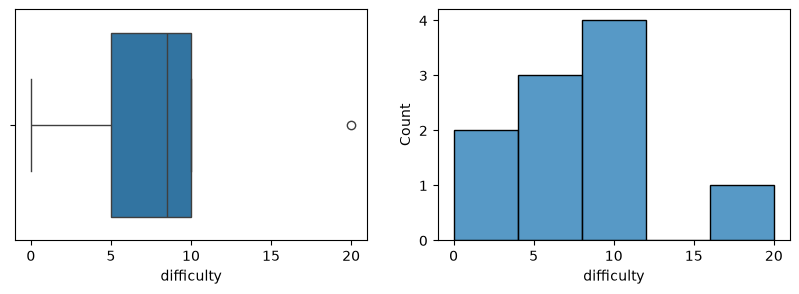

In [17]:
fig, axes = plt.subplots(1,2,figsize=(10,3))
sns.boxplot(data=df_offers, x='difficulty', ax=axes[0])
sns.histplot(data=df_offers, x='difficulty', ax=axes[1])

<Axes: xlabel='duration', ylabel='Count'>

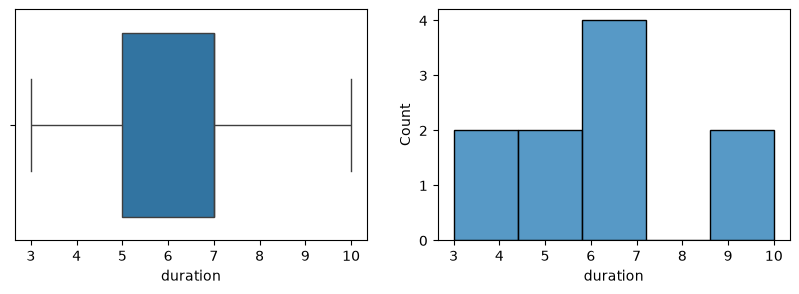

In [18]:
fig, axes = plt.subplots(1,2,figsize=(10,3))
sns.boxplot(data=df_offers, x='duration', ax=axes[0])
sns.histplot(data=df_offers, x='duration', ax=axes[1])

Conclusiones:
- Difficulty puede no ser un outlier porque puede tener sentido

## Outliers Events

In [21]:
# Analizamos el campo value para cada tipo de evento
display(df_events[df_events['event']=='offer received'].head(4))
display(df_events[df_events['event']=='offer completed'].head(4))
display(df_events[df_events['event']=='transaction'].head(4))

,customer_id,event,value,time
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0
1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0
2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0
3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},0


,customer_id,event,value,time
12658,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,offer completed,{'offer_id': '2906b810c7d4411798c6938adc9daaa5...,0
12672,fe97aa22dd3e48c8b143116a8403dd52,offer completed,{'offer_id': 'fafdcd668e3743c1bb461111dcafc2a4...,0
12679,629fc02d56414d91bca360decdfa9288,offer completed,{'offer_id': '9b98b8c7a33c4b65b9aebfe6a799e6d9...,0
12692,676506bad68e4161b9bbaffeb039626b,offer completed,{'offer_id': 'ae264e3637204a6fb9bb56bc8210ddfd...,0


,customer_id,event,value,time
12654,02c083884c7d45b39cc68e1314fec56c,transaction,{'amount': 0.8300000000000001},0
12657,9fa9ae8f57894cc9a3b8a9bbe0fc1b2f,transaction,{'amount': 34.56},0
12659,54890f68699049c2a04d415abc25e717,transaction,{'amount': 13.23},0
12670,b2f1cd155b864803ad8334cdf13c4bd2,transaction,{'amount': 19.51},0


Tipos de eventos y relación con value:
- Offer received: offer id
- Offer completed: offer_id y reward
- Transaction: amount

### vamos a normalizar la columna value con json_normalize para que pasen a formato tabla

In [22]:
df_events[df_events['customer_id'] == '78afa995795e4d85b5d9ceeca43f5fef'].sort_values(by='time')

,customer_id,event,value,time
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0
15561,78afa995795e4d85b5d9ceeca43f5fef,offer viewed,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},6
47582,78afa995795e4d85b5d9ceeca43f5fef,transaction,{'amount': 19.89},132
47583,78afa995795e4d85b5d9ceeca43f5fef,offer completed,{'offer_id': '9b98b8c7a33c4b65b9aebfe6a799e6d9...,132
49502,78afa995795e4d85b5d9ceeca43f5fef,transaction,{'amount': 17.78},144
53176,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '5a8bc65990b245e5a138643cd4eb9837'},168
85291,78afa995795e4d85b5d9ceeca43f5fef,offer viewed,{'offer id': '5a8bc65990b245e5a138643cd4eb9837'},216
87134,78afa995795e4d85b5d9ceeca43f5fef,transaction,{'amount': 19.67},222
92104,78afa995795e4d85b5d9ceeca43f5fef,transaction,{'amount': 29.72},240
141566,78afa995795e4d85b5d9ceeca43f5fef,transaction,{'amount': 23.93},378


# 2- Transformaciones

In [35]:
events_cleaned = df_events.copy()

In [36]:
#Cambiamos el tipo de dato de str a dict
events_cleaned['value'] = events_cleaned['value'].apply(ast.literal_eval)

In [37]:
type(events_cleaned.loc[0,'value'])

dict

In [38]:
normalized_value = pd.json_normalize(events_cleaned['value'])
normalized_value.sample(10)

,offer id,amount,offer_id,reward
236874,NaN,NaN,2906b810c7d4411798c6938adc9daaa5,2.0
288779,NaN,1.55,NaN,NaN
35581,NaN,0.94,NaN,NaN
221267,fafdcd668e3743c1bb461111dcafc2a4,NaN,NaN,NaN
177550,NaN,24.17,NaN,NaN
155989,f19421c1d4aa40978ebb69ca19b0e20d,NaN,NaN,NaN
36788,NaN,8.52,NaN,NaN
36542,NaN,28.40,NaN,NaN
183239,NaN,NaN,f19421c1d4aa40978ebb69ca19b0e20d,5.0
169724,NaN,0.69,NaN,NaN


In [39]:
events_final = pd.concat([events_cleaned, normalized_value], axis=1)
events_final.sample(10)

,customer_id,event,value,time,offer id,amount,offer_id,reward
10738,969b8fe3917b42a58147fd26ce80a8c2,offer received,{'offer id': '2298d6c36e964ae4a3e7e9706d1fb8c2'},0,2298d6c36e964ae4a3e7e9706d1fb8c2,NaN,NaN,NaN
83611,c4ee577a834d40df9037753d51151ba8,offer viewed,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},210,4d5c57ea9a6940dd891ad53e9dbe8da0,NaN,NaN,NaN
112550,cc479afdec8c4eca886f511ab031b915,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},336,0b1e1539f2cc45b7b9fa7c272da2e1d7,NaN,NaN,NaN
95782,ea817a9dae854c26b1cbf9fa52480194,transaction,{'amount': 18.02},252,NaN,18.02,NaN,NaN
23762,f035bb00515c408cbe7abfd7f70f8620,offer viewed,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},24,9b98b8c7a33c4b65b9aebfe6a799e6d9,NaN,NaN,NaN
267131,b82684c4183e46028854b30de1c3931f,transaction,{'amount': 9.94},588,NaN,9.94,NaN,NaN
291489,966e06d3aa76471792590bb78131e586,transaction,{'amount': 3.11},648,NaN,3.11,NaN,NaN
79628,1a297cc7262d42b59fb3e34fe0166702,transaction,{'amount': 1.6099999999999999},198,NaN,1.61,NaN,NaN
238818,127f660955454bd0a5a0d7b0a6a48c62,transaction,{'amount': 22.54},552,NaN,22.54,NaN,NaN
297203,4ffaeb221c214a6285349fe755d811d3,transaction,{'amount': 1.29},672,NaN,1.29,NaN,NaN


In [40]:
#*Borramos la columna value porque ya no nos sirve y juntamos las dos columnas offer_id y offer id
events_final['offer_id_combined'] = events_final['offer id'].fillna(events_final['offer_id'])
display(events_final.sample(7))

#* Eliminamos value, offer id y offer_id
events_final.drop(columns=['value', 'offer_id', 'offer id'], inplace=True)
events_final.rename(columns={'offer_id_combined': 'offer_id'}, inplace=True)

,customer_id,event,value,time,offer id,amount,offer_id,reward,offer_id_combined
302442,a9035280036b4e21bfe017153319c1b3,transaction,{'amount': 6.05},696,NaN,6.05,NaN,NaN,NaN
109479,4a8175a1b299409596276f93dd55a199,transaction,{'amount': 8.75},324,NaN,8.75,NaN,NaN,NaN
198299,5163b5cab2f74c678ec170cec67b6cd0,transaction,{'amount': 1.22},486,NaN,1.22,NaN,NaN,NaN
118474,351086383b524fab8199a86fd34edbbe,offer received,{'offer id': 'f19421c1d4aa40978ebb69ca19b0e20d'},336,f19421c1d4aa40978ebb69ca19b0e20d,NaN,NaN,NaN,f19421c1d4aa40978ebb69ca19b0e20d
4236,54b2518cb4684008a29d18137369eeb5,offer received,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},0,4d5c57ea9a6940dd891ad53e9dbe8da0,NaN,NaN,NaN,4d5c57ea9a6940dd891ad53e9dbe8da0
253230,cfe2e1e9fc0f4531bc7f653f3204b483,offer received,{'offer id': 'f19421c1d4aa40978ebb69ca19b0e20d'},576,f19421c1d4aa40978ebb69ca19b0e20d,NaN,NaN,NaN,f19421c1d4aa40978ebb69ca19b0e20d
35486,752afe8a3f9b492c9a8d2d051cf879e9,transaction,{'amount': 23.74},66,NaN,23.74,NaN,NaN,NaN


In [41]:
events_final.sample(10)

,customer_id,event,time,amount,reward,offer_id
263923,e6a14e7456dc4f53853648d0b08c7bc4,offer viewed,582,NaN,NaN,2298d6c36e964ae4a3e7e9706d1fb8c2
177514,b8089791382345409b4b0c090f67125e,offer viewed,432,NaN,NaN,9b98b8c7a33c4b65b9aebfe6a799e6d9
219237,53b793bee2d9403bb7e561120f2b3622,offer viewed,510,NaN,NaN,ae264e3637204a6fb9bb56bc8210ddfd
224472,0bab4b4713984db0ac68a9a42f6af163,transaction,516,20.01,NaN,NaN
164959,e685472e5137400db362c80bc216a915,offer viewed,408,NaN,NaN,fafdcd668e3743c1bb461111dcafc2a4
236375,7a5f624f754d4fceb346887164425f1d,transaction,546,6.34,NaN,NaN
32250,2520c1ca400d43f4bf52ed6f482a6a75,transaction,54,20.73,NaN,NaN
150277,9e8e79d141d743559be1aebceb0a9261,offer viewed,402,NaN,NaN,3f207df678b143eea3cee63160fa8bed
42924,1353dbe91e7d487ea07d84376ed1a221,transaction,102,17.45,NaN,NaN
256939,00fdd4416dec40b49180814c0a7c8d76,offer received,576,NaN,NaN,fafdcd668e3743c1bb461111dcafc2a4


Analizamos Nulls, outliers y cambios de tipo de variable

# 3. Analisis de Datos

Total de clientes que han hecho alguna transaccion en esos 30 dias de prueba

In [42]:
customers_clean.head()

,customer_id,became_member_on,gender,age,income
0,68be06ca386d4c31939f3a4f0e3dd783,2017-02-12,NaN,118,NaN
1,0610b486422d4921ae7d2bf64640c50b,2017-07-15,F,55,112000.0
2,38fe809add3b4fcf9315a9694bb96ff5,2018-07-12,NaN,118,NaN
3,78afa995795e4d85b5d9ceeca43f5fef,2017-05-09,F,75,100000.0
4,a03223e636434f42ac4c3df47e8bac43,2017-08-04,NaN,118,NaN


In [43]:
events_final.head()

,customer_id,event,time,amount,reward,offer_id
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,0,NaN,NaN,9b98b8c7a33c4b65b9aebfe6a799e6d9
1,a03223e636434f42ac4c3df47e8bac43,offer received,0,NaN,NaN,0b1e1539f2cc45b7b9fa7c272da2e1d7
2,e2127556f4f64592b11af22de27a7932,offer received,0,NaN,NaN,2906b810c7d4411798c6938adc9daaa5
3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,0,NaN,NaN,fafdcd668e3743c1bb461111dcafc2a4
4,68617ca6246f4fbc85e91a2a49552598,offer received,0,NaN,NaN,4d5c57ea9a6940dd891ad53e9dbe8da0


In [48]:
transactions = events_final[events_final['event']=='transaction']
print('Total transacciones: ', len(transactions))

print('Numeros de clientes con transaccion: ', transactions['customer_id'].nunique())

Total transacciones:  138953
Numeros de clientes con transaccion:  16578


In [50]:
transactions_by_client = transactions.groupby('customer_id').size().reset_index(name='number_transactions_by_client').sort_values(by='number_transactions_by_client', ascending=False)
transactions_by_client.head(10)

,customer_id,number_transactions_by_client
7887,79d9d4f86aca4bed9290350fb43817c2,36
9239,8dbfa485249f409aa223a2130f40634a,36
9702,94de646f7b6041228ca7dec82adb97d2,35
11652,b1f4ece7d49342628a9ed77aee2cde58,32
6118,5e60c6aa3b834e44b822ea43a3efea26,32
10740,a42ed50acc4d4b25bca647c9e0b916ad,31
2525,28681c16026943e68f26feaccab0907f,30
13558,d0a80415b84c4df4908b8403b19765e3,30
11192,ab25fd6fbd5040f880751921e4029757,30
4215,40ce078d5b2a43d19138a788754520be,30


<Axes: xlabel='number_transactions_by_client', ylabel='Count'>

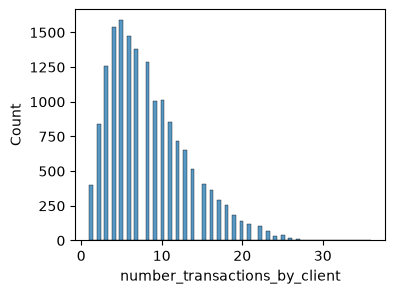

In [52]:
#Visualizacion
plt.figure(figsize=(4,3))
sns.histplot(data=transactions_by_client,  x= 'number_transactions_by_client')

In [53]:
# Segmentacion de clientes

non_returning_clients = transactions_by_client[transactions_by_client['number_transactions_by_client'] == 1]
returning_clients = transactions_by_client[(transactions_by_client['number_transactions_by_client'] > 1) & (transactions_by_client['number_transactions_by_client'] <= 20)]
top_clients = transactions_by_client[transactions_by_client['number_transactions_by_client'] > 20]

In [60]:
# Gasto medio en cada segmento de clientes
#Top Clients
top_clients_purchase = events_final[(events_final['customer_id'].isin(top_clients['customer_id'])) & (events_final['event']=='transaction')]['amount']
top_clients_purchase.mean()

6.660172413793103

In [61]:
#Non returning clients
non_returning_purchase = events_final[(events_final['customer_id'].isin(non_returning_clients['customer_id'])) & (events_final['event']=='transaction')]['amount']
non_returning_purchase.mean()

13.402369077306734

In [62]:
# Returning clients
returning_clients_purchase = events_final[(events_final['customer_id'].isin(returning_clients['customer_id'])) & (events_final['event']=='transaction')]['amount']
returning_clients_purchase.mean()

13.22928602440651

In [56]:
#Media general 
events_final['amount'].mean()

12.77735615639821

In [63]:
# Cual es el total de ingresos por cada segmento de clientes
print('Total top clientes: ', top_clients_purchase.sum())
print('Total no returning clients: ', non_returning_purchase.sum())


Total top clientes:  63737.85
Total no returning clients:  5374.35


### Funnel de ofertas

In [64]:
events_final[events_final['event'] != 'transaction']['event'].value_counts().reset_index(name='count')

,event,count
0,offer received,76277
1,offer viewed,57725
2,offer completed,33579
